# 04 Time Patterns

**Question:** How do KPIs change by day, weekday and hour?

Task 2, step 4: **KPIs by day, weekday and hour of day, with a rolling 7-day average to separate trend from noise**. Unusual days and hours are flagged with **z-scores against a baseline**.

**Rules carried over from Notebook 02:**
* Clicks and conversions are linked to their impression (bid_id + user + nearest earlier impression), and counted on the **impression's date and hour**. So a day's CTR uses that day's impressions.
* CTR = clicked impressions / impressions, with a 95% Wilson interval. Every rate is a **ratio of sums**, and so is the rolling average: it is `sum(clicks over 7 days) / sum(impressions over 7 days)`, not the mean of 7 daily CTRs.
* Spend = `sum(paying_price) / 1000` (scaled units).

**Two limits of this dataset** (6–12 June 2013, Thursday to Wednesday):
1. **Each weekday appears exactly once**, so a "weekday effect" can't be separated from whatever else happened that day.
2. A **7-day rolling window only fills on the last day**. With 7 days, it is a cumulative average, which is still the right baseline to judge each day against, but it can't show a trend. The **hour-of-day** pattern (7 × 24 = 168 hours) and the rolling **24-hour** window are the more reliable signals here.

Timestamps are the log's own clock: Beijing time, UTC+8.

### Setup

In [1]:
# CELL 1: setup (read-only connection)
from pathlib import Path
import os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

KILL_STALE = False
Z_FLAG = 3.0           # |z| above this = unusual
PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            m = re.search(r"PID (\d+)", str(e))
            if "lock" not in str(e).lower() or m is None:
                raise
            print(f"The database is locked by another Python process (PID {m.group(1)}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            os.kill(int(m.group(1)), signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")
except Exception:
    pass
q = lambda sql: con.execute(sql).df()

views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
assert {"typed_imp", "typed_clk", "typed_conv"} <= views, "Run the loading cells first"
if "raw_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    con.execute("CREATE TEMP VIEW raw_bid AS SELECT * FROM read_parquet([" + ", ".join(f"'{x}'" for x in files) + "])")
    print("raw_bid rebuilt in memory from", len(files), "Parquet files")

def wilson(k, n, z=1.959964):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        d = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.where(n > 0, c - h, np.nan), np.where(n > 0, c + h, np.nan)

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mt
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": "#e6e5e0", "axes.titlesize": 10, "axes.titleweight": "bold",
                         "axes.titlelocation": "left", "font.size": 9})
except ImportError:
    plt = None
    print("pip install matplotlib for the charts")
BLUE, ORANGE, RED, INK2, GREY = "#2a78d6", "#eb6834", "#e34948", "#52514e", "#8a8984"
CAMP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cf6", "#c2410c"]
pct3 = lambda: mt.PercentFormatter(1.0, decimals=3)

def save(fig, name):
    try:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except OSError:
        print(f"(no disk space: {name}.png not saved)")
print("Data:", DATA_SOURCE)

Data: ipinyou.duckdb (the loading notebook's database)


### 1. Hourly building blocks

Everything below is built from one small table: **campaign × date × hour**, holding bids, impressions, spend, clicked impressions and converted impressions. That is at most 5 × 7 × 24 = 840 rows, and every day, weekday or hour view is a sum over it.

The click and conversion linking is the same as in Notebook 02, done in memory on the few thousand impressions that were clicked or converted.

In [2]:
# CELL 2: build the campaign x date x hour table
t0 = time.time()
imp_h = q("""SELECT advertiser_id, log_date AS date, hour(timestamp) AS hour,
                    count(*) AS imps, sum(paying_price) / 1000.0 AS spend
             FROM typed_imp GROUP BY ALL""")
print(f"impressions aggregated ({time.time() - t0:.0f}s)")

t0 = time.time()
# bids: read the hour straight from the timestamp text (yyyyMMddHH...) - cheaper than parsing 53M timestamps
bid_h = q("""SELECT TRY_CAST(advertiser_id AS BIGINT) AS advertiser_id,
                    regexp_extract(filename, '([0-9]+)\\.txt$', 1) AS date,
                    TRY_CAST(substr(timestamp, 9, 2) AS INTEGER) AS hour, count(*) AS bids
             FROM raw_bid GROUP BY ALL""")
print(f"bids aggregated ({time.time() - t0:.0f}s)")

# link clicks and conversions to impressions (the Notebook 02 rule), in memory
con.execute("""
CREATE OR REPLACE TEMP TABLE imp_c AS
SELECT DISTINCT bid_id, ipinyou_id, timestamp AS imp_ts, log_date AS imp_date, advertiser_id,
       hash(bid_id, ipinyou_id, timestamp) AS imp_key
FROM typed_imp WHERE bid_id IN (SELECT bid_id FROM typed_clk UNION SELECT bid_id FROM typed_conv)""")
for log in ["clk", "conv"]:
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE {log}_m AS
    WITH e AS (SELECT row_number() OVER () AS ev_id, bid_id, ipinyou_id, timestamp AS ev_ts
               FROM (SELECT DISTINCT * FROM typed_{log})),
    m1 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i
           ON e.bid_id = i.bid_id AND e.ipinyou_id = i.ipinyou_id AND e.ev_ts >= i.imp_ts),
    m2 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i ON e.bid_id = i.bid_id AND e.ev_ts >= i.imp_ts),
    m3 AS (SELECT e.ev_id, arg_min(i.imp_key, abs(epoch(e.ev_ts) - epoch(i.imp_ts))) AS imp_key
           FROM e JOIN imp_c i USING (bid_id) GROUP BY 1)
    SELECT e.ev_id, coalesce(m1.imp_key, m2.imp_key, m3.imp_key) AS imp_key
    FROM e LEFT JOIN m1 USING (ev_id) LEFT JOIN m2 USING (ev_id) LEFT JOIN m3 USING (ev_id)""")
ev_h = q("""
    WITH k AS (SELECT DISTINCT imp_key FROM clk_m WHERE imp_key IS NOT NULL),
         v AS (SELECT DISTINCT imp_key FROM conv_m WHERE imp_key IS NOT NULL)
    SELECT i.advertiser_id, i.imp_date AS date, hour(i.imp_ts) AS hour,
           count(*) FILTER (WHERE k.imp_key IS NOT NULL) AS clicks,
           count(*) FILTER (WHERE v.imp_key IS NOT NULL) AS convs
    FROM (SELECT DISTINCT imp_key, advertiser_id, imp_date, imp_ts FROM imp_c) i
    LEFT JOIN k USING (imp_key) LEFT JOIN v USING (imp_key)
    WHERE k.imp_key IS NOT NULL OR v.imp_key IS NOT NULL
    GROUP BY ALL""")

keys = ["advertiser_id", "date", "hour"]
H = (bid_h.merge(imp_h, on=keys, how="outer").merge(ev_h, on=keys, how="outer").fillna(0))
H = H[H.date.astype(str).str.len() == 8]
for c in ["bids", "imps", "clicks", "convs", "advertiser_id", "hour"]:
    H[c] = H[c].astype("int64")
H["date"] = pd.to_datetime(H.date.astype(str), format="%Y%m%d")
print(f"hourly table: {len(H):,} rows | totals: {H.bids.sum():,} bids, {H.imps.sum():,} impressions, "
      f"{H.clicks.sum():,} clicked impressions, {H.convs.sum():,} converted impressions")

def kpis(df):
    """KPIs as ratios of sums, with Wilson CIs on CTR and win rate."""
    df = df.copy()
    df["win_rate"] = df.imps / df.bids.where(df.bids > 0)
    df["ctr"] = df.clicks / df.imps.where(df.imps > 0)
    df["ctr_lo"], df["ctr_hi"] = wilson(df.clicks, df.imps)
    df["cvr"] = df.convs / df.clicks.where(df.clicks > 0)
    df["cpm"] = 1000 * df.spend / df.imps.where(df.imps > 0)
    df["cpc"] = df.spend / df.clicks.where(df.clicks > 0)
    df["cpa"] = df.spend / df.convs.where(df.convs > 0)
    return df

SUMS = ["bids", "imps", "spend", "clicks", "convs"]
FMT = {"bids": "{:,.0f}", "imps": "{:,.0f}", "spend": "{:,.0f}", "clicks": "{:,.0f}", "convs": "{:,.0f}",
       "win_rate": "{:.2%}", "ctr": "{:.3%}", "ctr_lo": "{:.3%}", "ctr_hi": "{:.3%}", "cvr": "{:.1%}",
       "cpm": "{:.1f}", "cpc": "{:.1f}", "cpa": "{:,.0f}"}

impressions aggregated (0s)
bids aggregated (1s)
hourly table: 751 rows | totals: 53,289,330 bids, 12,237,087 impressions, 8,751 clicked impressions, 391 converted impressions


### 2. By day, with a rolling 7-day baseline

* **rolling 7-day** = the sums over the last 7 days (up to the day itself), then the ratio. Here it covers fewer days early in the week and becomes a full 7-day window only on 12 June.
* **z-score for CTR**: how far the day's CTR is from the baseline of *the days before it*, in standard errors: `z = (CTR_day − CTR_base) / sqrt(CTR_base × (1 − CTR_base) / impressions_day)`. |z| > 3 is unusual: random noise gives that about 3 times in 1,000.
* **z-score for volume** (impressions, spend): the day vs the mean and standard deviation of the days before it. It needs at least 3 earlier days.

Days are compared within each campaign, because campaigns differ in size.

In [3]:
# CELL 3: daily KPIs, rolling 7-day, z-scores (per campaign and in total)
def daily_with_baseline(h):
    d = kpis(h.groupby("date")[SUMS].sum().sort_index())
    roll = d[SUMS].rolling(7, min_periods=1).sum()
    d["days_in_window"] = d.imps.rolling(7, min_periods=1).count().astype(int)
    d["ctr_7d"] = roll.clicks / roll.imps
    d["win_rate_7d"] = roll.imps / roll.bids.where(roll.bids > 0)
    d["cpm_7d"] = 1000 * roll.spend / roll.imps
    prev = d[SUMS].shift(1).rolling(7, min_periods=1).sum()
    base = prev.clicks / prev.imps
    d["ctr_baseline"] = base
    d["ctr_z"] = (d.ctr - base) / np.sqrt(base * (1 - base) / d.imps)
    for c in ["imps", "spend"]:
        m = d[c].shift(1).rolling(7, min_periods=3).mean()
        s = d[c].shift(1).rolling(7, min_periods=3).std()
        d[f"{c}_z"] = (d[c] - m) / s
    d["flag"] = (d[["ctr_z", "imps_z", "spend_z"]].abs() > Z_FLAG).any(axis=1)
    return d

daily = {"ALL": daily_with_baseline(H)}
for adv in sorted(H.advertiser_id.unique()):
    daily[adv] = daily_with_baseline(H[H.advertiser_id == adv])

cols = ["bids", "imps", "win_rate", "clicks", "ctr", "ctr_lo", "ctr_hi", "ctr_7d", "convs", "cvr", "spend",
        "cpm", "cpc", "ctr_z", "imps_z", "spend_z", "flag"]
print("All campaigns, by day:")
display(daily["ALL"][cols].style.format({**FMT, "ctr_7d": "{:.3%}", "ctr_z": "{:+.1f}", "imps_z": "{:+.1f}",
                                         "spend_z": "{:+.1f}"}, na_rep="–"))

flags = pd.concat([d.assign(campaign=str(k)) for k, d in daily.items()]).reset_index()
flags = flags[flags.flag][["campaign", "date", "imps", "clicks", "ctr", "ctr_baseline", "ctr_z", "imps_z", "spend_z"]]
print(f"Unusual campaign-days (|z| > {Z_FLAG:g}):")
display(flags.style.format({"imps": "{:,.0f}", "clicks": "{:,.0f}", "ctr": "{:.3%}", "ctr_baseline": "{:.3%}",
                            "ctr_z": "{:+.1f}", "imps_z": "{:+.1f}", "spend_z": "{:+.1f}"}, na_rep="–"))

print("Impressions per campaign per day:")
display(pd.DataFrame({k: d.imps for k, d in daily.items() if k != "ALL"}).style.format("{:,.0f}"))

All campaigns, by day:


,bids,imps,win_rate,clicks,ctr,ctr_lo,ctr_hi,ctr_7d,convs,cvr,spend,cpm,cpc,ctr_z,imps_z,spend_z,flag
date,,,,,,,,,,,,,,,,,
2013-06-06 00:00:00,"9,586,949","1,821,350",19.00%,"1,150",0.063%,0.060%,0.067%,0.063%,38,3.3%,"136,349",74.9,118.6,–,–,–,False
2013-06-07 00:00:00,"11,132,555","1,805,953",16.22%,"1,044",0.058%,0.054%,0.061%,0.060%,43,4.1%,"130,587",72.3,125.1,-2.9,–,–,False
2013-06-08 00:00:00,"5,226,937","1,634,830",31.28%,"1,156",0.071%,0.067%,0.075%,0.064%,35,3.0%,"132,647",81.1,114.7,+5.3,–,–,True
2013-06-09 00:00:00,"11,880,893","1,651,524",13.90%,"1,140",0.069%,0.065%,0.073%,0.065%,29,2.5%,"134,291",81.3,117.8,+2.7,-1.0,+0.4,False
2013-06-10 00:00:00,"5,610,729","1,920,370",34.23%,"1,522",0.079%,0.075%,0.083%,0.068%,108,7.1%,"153,303",79.8,100.7,+7.8,+1.9,+8.1,True
2013-06-11 00:00:00,"5,094,845","1,745,722",34.26%,"1,379",0.079%,0.075%,0.083%,0.070%,50,3.6%,"138,992",79.6,100.8,+5.5,-0.2,+0.2,True
2013-06-12 00:00:00,"4,756,422","1,657,338",34.84%,"1,360",0.082%,0.078%,0.087%,0.072%,88,6.5%,"132,570",80.0,97.5,+5.9,-1.0,-0.6,True


Unusual campaign-days (|z| > 3):


,campaign,date,imps,clicks,ctr,ctr_baseline,ctr_z,imps_z,spend_z
2,ALL,2013-06-08 00:00:00,"1,634,830","1,156",0.071%,0.060%,+5.3,–,–
4,ALL,2013-06-10 00:00:00,"1,920,370","1,522",0.079%,0.065%,+7.8,+1.9,+8.1
5,ALL,2013-06-11 00:00:00,"1,745,722","1,379",0.079%,0.068%,+5.5,-0.2,+0.2
6,ALL,2013-06-12 00:00:00,"1,657,338","1,360",0.082%,0.070%,+5.9,-1.0,-0.6
9,1458,2013-06-08 00:00:00,"413,804",339,0.082%,0.068%,+3.4,–,–
12,1458,2013-06-11 00:00:00,"437,520",395,0.090%,0.077%,+3.3,-0.1,-0.2
17,3358,2013-06-09 00:00:00,"149,618",76,0.051%,0.059%,-1.3,-4.4,-4.3
18,3358,2013-06-10 00:00:00,"463,542",427,0.092%,0.057%,+9.9,+15.1,+19.9
20,3358,2013-06-12 00:00:00,"335,310",303,0.090%,0.073%,+3.8,+0.9,+1.2
24,3386,2013-06-09 00:00:00,"395,406",268,0.068%,0.063%,+1.1,-0.7,+10.7


Impressions per campaign per day:


,1458,3358,3386,3427,3476
date,,,,,
2013-06-06 00:00:00,"448,164","189,372","435,900","393,516","354,398"
2013-06-07 00:00:00,"478,109","190,502","444,191","323,320","369,831"
2013-06-08 00:00:00,"413,804","175,916","381,363","351,794","311,953"
2013-06-09 00:00:00,"423,726","149,618","395,406","383,389","299,385"
2013-06-10 00:00:00,"434,240","463,542","385,766","371,824","264,998"
2013-06-11 00:00:00,"437,520","237,844","412,275","379,524","278,559"
2013-06-12 00:00:00,"447,493","335,310","392,901","390,398","91,236"


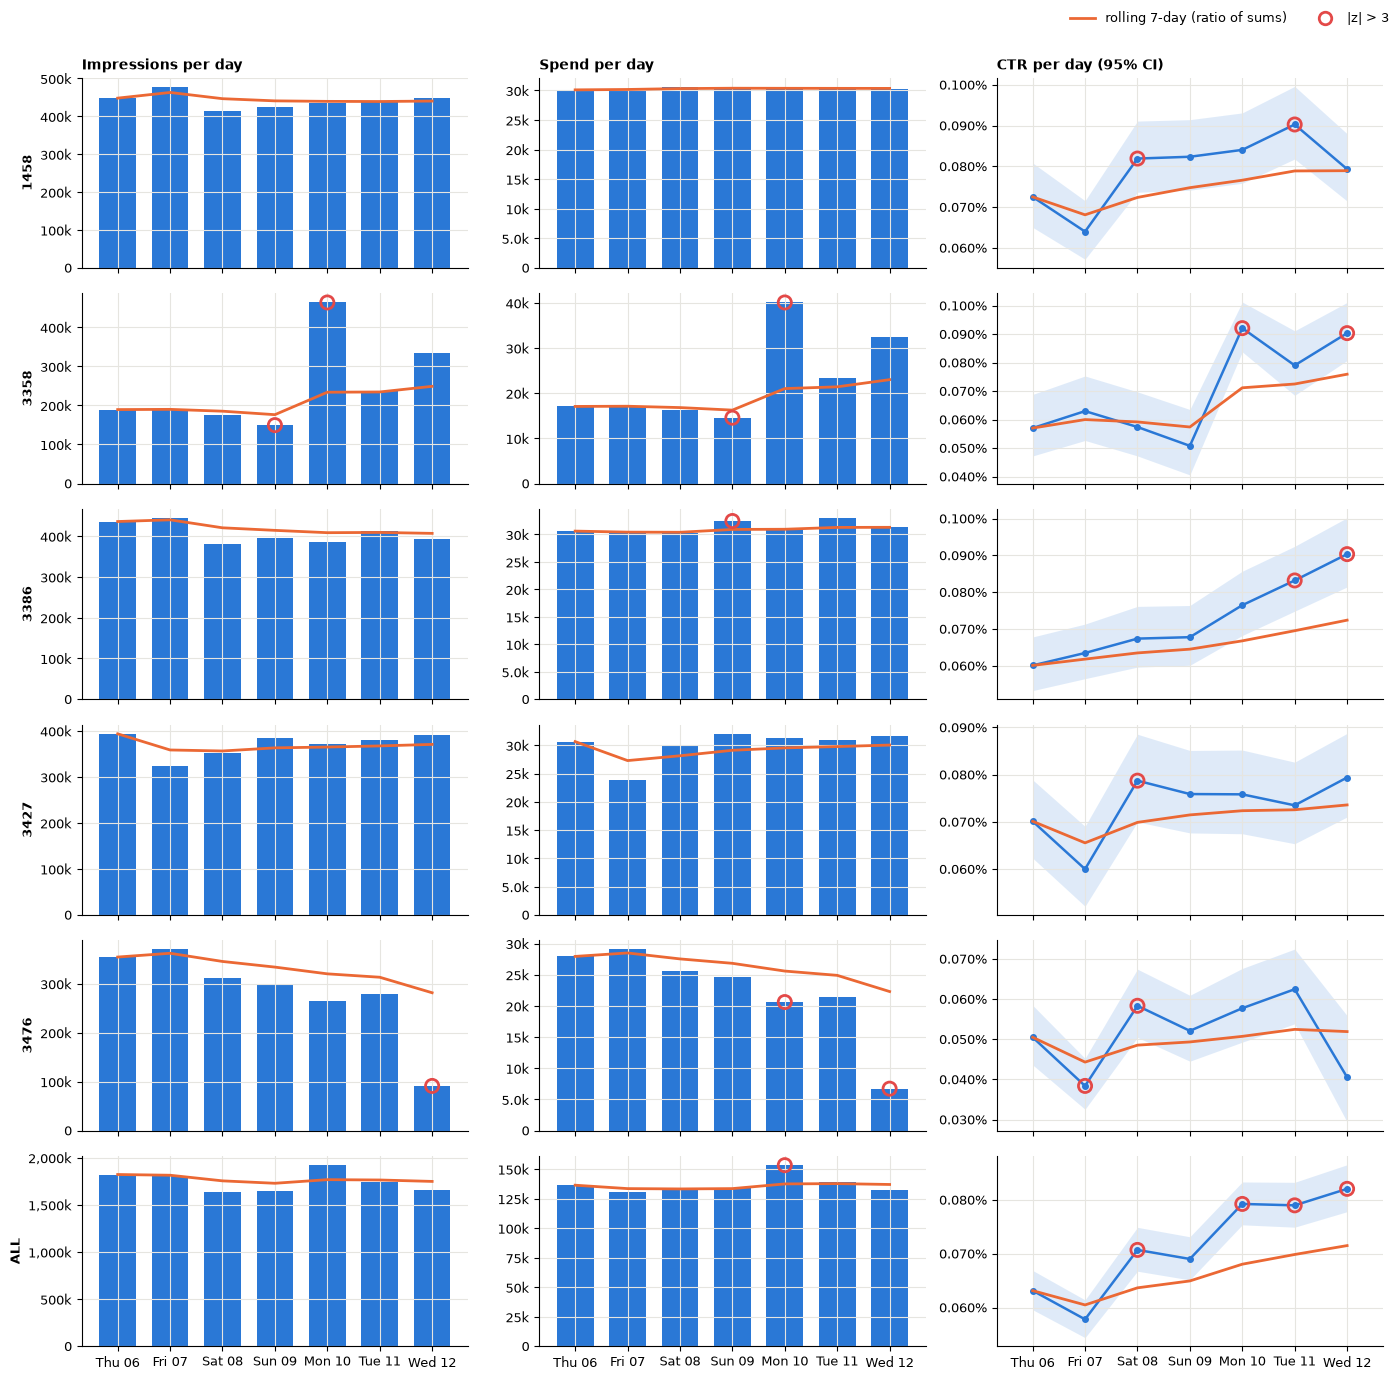

In [4]:
# CELL 4: daily chart, one row per campaign: impressions | spend | CTR with 95% CI and the rolling 7-day CTR
if plt:
    camps = [k for k in daily if k != "ALL"] + ["ALL"]
    fig, axes = plt.subplots(len(camps), 3, figsize=(14, 2.3 * len(camps)), sharex=True)
    for row, k in zip(axes, camps):
        d = daily[k]
        x = d.index
        row[0].bar(x, d.imps, color=BLUE, width=0.7)
        row[0].plot(x, d.imps.rolling(7, min_periods=1).mean(), color=ORANGE, lw=2)
        row[0].set_ylabel(str(k), fontweight="bold")
        row[1].bar(x, d.spend, color=BLUE, width=0.7)
        row[1].plot(x, d.spend.rolling(7, min_periods=1).mean(), color=ORANGE, lw=2)
        row[2].fill_between(x, d.ctr_lo, d.ctr_hi, color=BLUE, alpha=0.15, lw=0)
        row[2].plot(x, d.ctr, color=BLUE, marker="o", ms=4, lw=1.8)
        row[2].plot(x, d.ctr_7d, color=ORANGE, lw=2)
        row[2].yaxis.set_major_formatter(pct3())
        for ax, col, zc in ((row[0], "imps", "imps_z"), (row[1], "spend", "spend_z"), (row[2], "ctr", "ctr_z")):
            f = d[d[zc].abs() > Z_FLAG]                      # each panel marks its own unusual days
            ax.scatter(f.index, f[col], s=90, facecolor="none", edgecolor=RED, lw=2, zorder=5)
            ax.yaxis.set_major_formatter(pct3() if col == "ctr" else
                                         mt.FuncFormatter(lambda v, _: f"{v / 1e3:,.1f}k" if 1e3 <= v < 1e4
                                                          else (f"{v / 1e3:,.0f}k" if v >= 1e4 else f"{v:,.0f}")))
    for ax, t in zip(axes[0], ["Impressions per day", "Spend per day", "CTR per day (95% CI)"]):
        ax.set_title(t)
    for ax in axes[-1]:
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d"))
    fig.legend([plt.Line2D([], [], color=ORANGE, lw=2),
                plt.Line2D([], [], marker="o", ls="", mfc="none", mec=RED, mew=2, ms=9)],
               ["rolling 7-day (ratio of sums)", f"|z| > {Z_FLAG:g}"], loc="upper right", frameon=False, ncol=2)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    save(fig, "04_daily_by_campaign")
    plt.show()

### 3. By weekday

With one week of data, each weekday is a single date, so this table is the daily table relabelled. It is shown because the brief asks for it. Read any difference as *"that Saturday was different"*, not *"Saturdays are different"*: one week can't separate a weekday effect from a one-off event.

In [5]:
# CELL 5: by weekday (all campaigns, then CTR per campaign)
wd = H.assign(weekday=H.date.dt.day_name(), wd_num=H.date.dt.dayofweek)
by_wd = kpis(wd.groupby(["wd_num", "weekday"])[SUMS].sum()).reset_index(level=0, drop=True)
by_wd["dates_in_data"] = wd.groupby("weekday").date.nunique().reindex(by_wd.index)
display(by_wd[["dates_in_data", "imps", "win_rate", "clicks", "ctr", "ctr_lo", "ctr_hi", "cvr", "spend", "cpm"]]
        .style.format(FMT, na_rep="–"))
ctr_wd = kpis(wd.groupby(["advertiser_id", "wd_num", "weekday"])[SUMS].sum()).reset_index()
display(ctr_wd.pivot_table(index=["wd_num", "weekday"], columns="advertiser_id", values="ctr")
        .droplevel(0).style.format("{:.3%}"))

/var/folders/vr/5sr6q8096vd7rsf7r7sy60dw0000gn/T/ipykernel_13662/3557306112.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  wd = H.assign(weekday=H.date.dt.day_name(), wd_num=H.date.dt.dayofweek)


,dates_in_data,imps,win_rate,clicks,ctr,ctr_lo,ctr_hi,cvr,spend,cpm
weekday,,,,,,,,,,
Monday,1,"1,920,370",34.23%,"1,522",0.079%,0.075%,0.083%,7.1%,"153,303",79.8
Tuesday,1,"1,745,722",34.26%,"1,379",0.079%,0.075%,0.083%,3.6%,"138,992",79.6
Wednesday,1,"1,657,338",34.84%,"1,360",0.082%,0.078%,0.087%,6.5%,"132,570",80.0
Thursday,1,"1,821,350",19.00%,"1,150",0.063%,0.060%,0.067%,3.3%,"136,349",74.9
Friday,1,"1,805,953",16.22%,"1,044",0.058%,0.054%,0.061%,4.1%,"130,587",72.3
Saturday,1,"1,634,830",31.28%,"1,156",0.071%,0.067%,0.075%,3.0%,"132,647",81.1
Sunday,1,"1,651,524",13.90%,"1,140",0.069%,0.065%,0.073%,2.5%,"134,291",81.3


advertiser_id,1458,3358,3386,3427,3476
weekday,,,,,
Monday,0.084%,0.092%,0.076%,0.076%,0.058%
Tuesday,0.090%,0.079%,0.083%,0.074%,0.062%
Wednesday,0.079%,0.090%,0.090%,0.079%,0.041%
Thursday,0.073%,0.057%,0.060%,0.070%,0.051%
Friday,0.064%,0.063%,0.063%,0.060%,0.038%
Saturday,0.082%,0.057%,0.067%,0.079%,0.058%
Sunday,0.082%,0.051%,0.068%,0.076%,0.052%


### 4. By hour of day

This is the most reliable time pattern here: each hour is observed on 7 days. It has two parts:
* **Volume**: impressions and spend per hour. This is where the budget goes during the day, the raw material for the **pacing** tab.
* **Response**: CTR per hour with a 95% CI. Where two hours' intervals don't overlap, the difference is very unlikely to be noise. A **chi-square test** checks whether CTR differs across the 24 hours at all, before any single hour is singled out.

In [6]:
# CELL 6: hour-of-day KPIs (all campaigns), chi-square test, and per-campaign CTR
by_hour = kpis(H.groupby("hour")[SUMS].sum())
by_hour["imp_share"] = by_hour.imps / by_hour.imps.sum()
by_hour["spend_share"] = by_hour.spend / by_hour.spend.sum()
display(by_hour[["bids", "imps", "imp_share", "spend_share", "win_rate", "clicks", "ctr", "ctr_lo", "ctr_hi",
                 "cvr", "cpm", "cpc"]].style.format({**FMT, "imp_share": "{:.1%}", "spend_share": "{:.1%}"}, na_rep="–"))

def chi2_homogeneity(clicks, imps):
    """Is CTR the same in every group? Pearson chi-square on the 2 x k table."""
    clicks, imps = np.asarray(clicks, float), np.asarray(imps, float)
    p = clicks.sum() / imps.sum()
    exp_c, exp_n = imps * p, imps * (1 - p)
    stat = (((clicks - exp_c) ** 2) / exp_c + (((imps - clicks) - exp_n) ** 2) / exp_n).sum()
    dof = len(imps) - 1
    try:
        from scipy.stats import chi2
        pval = chi2.sf(stat, dof)
    except ImportError:
        pval = np.nan
    return stat, dof, pval

rows = []
for adv in ["ALL"] + sorted(H.advertiser_id.unique()):
    h = H if adv == "ALL" else H[H.advertiser_id == adv]
    bh = h.groupby("hour")[["clicks", "imps"]].sum()
    stat, dof, pval = chi2_homogeneity(bh.clicks, bh.imps)
    k = kpis(h.groupby("hour")[SUMS].sum())
    big = k[k.imps >= k.imps.sum() / 24 * 0.25]          # ignore very thin hours
    rows.append({"campaign": adv, "chi2": stat, "dof": dof, "p_value": pval,
                 "best_hour": int(big.ctr.idxmax()), "best_ctr": big.ctr.max(),
                 "worst_hour": int(big.ctr.idxmin()), "worst_ctr": big.ctr.min(),
                 "best/worst": big.ctr.max() / big.ctr.min() if big.ctr.min() > 0 else np.nan,
                 "peak_volume_hour": int(k.imps.idxmax())})
hour_tests = pd.DataFrame(rows)
print("Does CTR differ by hour? (chi-square test of homogeneity; p < 0.05 = yes)")
display(hour_tests.style.format({"chi2": "{:.1f}", "p_value": "{:.2g}", "best_ctr": "{:.3%}",
                                 "worst_ctr": "{:.3%}", "best/worst": "{:.2f}"}, na_rep="(install scipy)"))

,bids,imps,imp_share,spend_share,win_rate,clicks,ctr,ctr_lo,ctr_hi,cvr,cpm,cpc
hour,,,,,,,,,,,,
0,"4,149,016","1,019,254",8.3%,10.1%,24.57%,813,0.080%,0.074%,0.085%,10.7%,95.2,119.4
1,"4,054,524","302,155",2.5%,2.2%,7.45%,210,0.070%,0.061%,0.080%,4.8%,71.2,102.5
2,"2,346,841","162,344",1.3%,1.1%,6.92%,96,0.059%,0.048%,0.072%,7.3%,65.1,110.0
3,"740,134","152,386",1.2%,1.1%,20.59%,99,0.065%,0.053%,0.079%,2.0%,69.1,106.4
4,"394,262","79,603",0.7%,0.6%,20.19%,51,0.064%,0.049%,0.084%,5.9%,67.4,105.2
5,"342,495","87,301",0.7%,0.6%,25.49%,74,0.085%,0.068%,0.106%,6.8%,68.5,80.8
6,"259,056","110,007",0.9%,0.8%,42.46%,69,0.063%,0.050%,0.079%,7.2%,74.0,118.0
7,"542,514","249,973",2.0%,2.0%,46.08%,184,0.074%,0.064%,0.085%,0.0%,77.4,105.1
8,"851,135","356,247",2.9%,3.0%,41.86%,217,0.061%,0.053%,0.070%,3.7%,79.6,130.7


Does CTR differ by hour? (chi-square test of homogeneity; p < 0.05 = yes)


,campaign,chi2,dof,p_value,best_hour,best_ctr,worst_hour,worst_ctr,best/worst,peak_volume_hour
0,ALL,154.6,23,(install scipy),23,0.087%,9,0.053%,1.66,0
1,1458,57.9,23,(install scipy),21,0.103%,10,0.058%,1.76,22
2,3358,88.7,23,(install scipy),19,0.108%,14,0.038%,2.82,0
3,3386,79.1,23,(install scipy),23,0.098%,3,0.042%,2.33,0
4,3427,37.0,23,(install scipy),3,0.092%,2,0.049%,1.87,16
5,3476,45.0,23,(install scipy),19,0.070%,23,0.025%,2.77,10


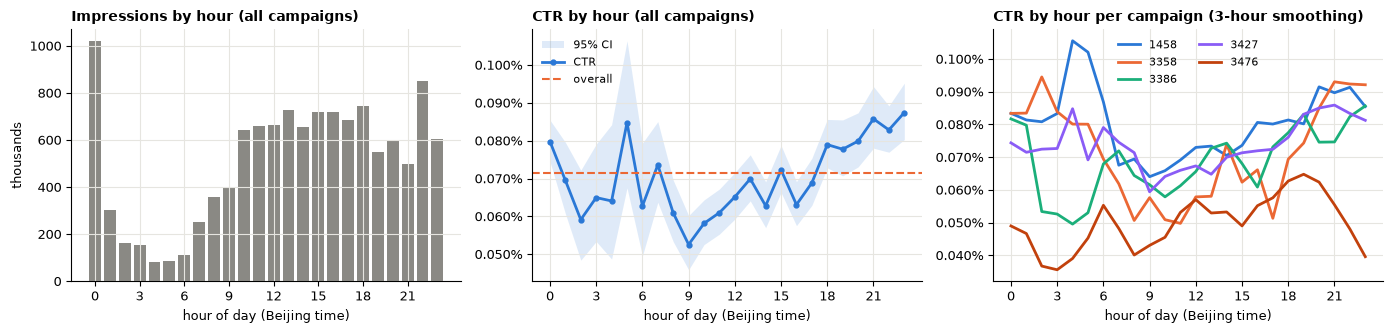

In [7]:
# CELL 7: hour-of-day charts
if plt:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
    axes[0].bar(by_hour.index, by_hour.imps / 1e3, color=GREY, width=0.8)
    axes[0].set_title("Impressions by hour (all campaigns)")
    axes[0].set_ylabel("thousands")
    ax = axes[1]
    ax.fill_between(by_hour.index, by_hour.ctr_lo, by_hour.ctr_hi, color=BLUE, alpha=0.15, lw=0, label="95% CI")
    ax.plot(by_hour.index, by_hour.ctr, color=BLUE, lw=2, marker="o", ms=3.5, label="CTR")
    tot = H.clicks.sum() / H.imps.sum()
    ax.axhline(tot, color=ORANGE, ls="--", lw=1.5, label="overall")
    ax.yaxis.set_major_formatter(pct3())
    ax.set_title("CTR by hour (all campaigns)")
    ax.legend(fontsize=8, frameon=False)
    ax = axes[2]
    for adv, c in zip(sorted(H.advertiser_id.unique()), CAMP_COLORS):
        k = kpis(H[H.advertiser_id == adv].groupby("hour")[SUMS].sum())
        k["ctr_s"] = k.clicks.rolling(3, center=True, min_periods=1).sum() / k.imps.rolling(3, center=True, min_periods=1).sum()
        ax.plot(k.index, k.ctr_s, color=c, lw=2, label=str(adv))
    ax.yaxis.set_major_formatter(pct3())
    ax.set_title("CTR by hour per campaign (3-hour smoothing)")
    ax.legend(fontsize=8, frameon=False, ncol=2)
    for a in axes:
        a.set_xticks(range(0, 24, 3))
        a.set_xlabel("hour of day (Beijing time)")
    fig.tight_layout()
    save(fig, "04_hour_of_day")
    plt.show()

### 5. Hour by hour across the week: rolling 24-hour CTR and unusual hours

The 168 hours as one series. The **rolling 24-hour CTR** (sums over the last 24 hours) shows the trend without the daily cycle. Each hour is also compared with **the same hour of the day on the other days**. That way the evening peak isn't flagged just for being evening; only a truly unusual hour is.

Unusual hours (|z| > 3 vs the same hour on other days): 11 of 168


,ts,imps,clicks,ctr,ctr_same_hour_baseline,ctr_z,imps_z
27,2013-06-07 03:00:00,"22,816",2,0.009%,0.075%,-3.7,+0.3
36,2013-06-07 12:00:00,"111,575",45,0.040%,0.070%,-3.8,+1.5
38,2013-06-07 14:00:00,"110,208",47,0.043%,0.067%,-3.1,+2.2
108,2013-06-10 12:00:00,"77,737",70,0.090%,0.062%,+3.2,-1.6
118,2013-06-10 22:00:00,"419,310",376,0.090%,0.076%,+3.2,+2.6
128,2013-06-11 08:00:00,"76,864",69,0.090%,0.053%,+4.4,+2.1
135,2013-06-11 15:00:00,"135,099",124,0.092%,0.068%,+3.4,+2.2
144,2013-06-12 00:00:00,"278,757",260,0.093%,0.075%,+3.6,+2.3
145,2013-06-12 01:00:00,"96,224",85,0.088%,0.061%,+3.5,+2.4
158,2013-06-12 14:00:00,"90,009",94,0.104%,0.056%,+6.1,-0.5


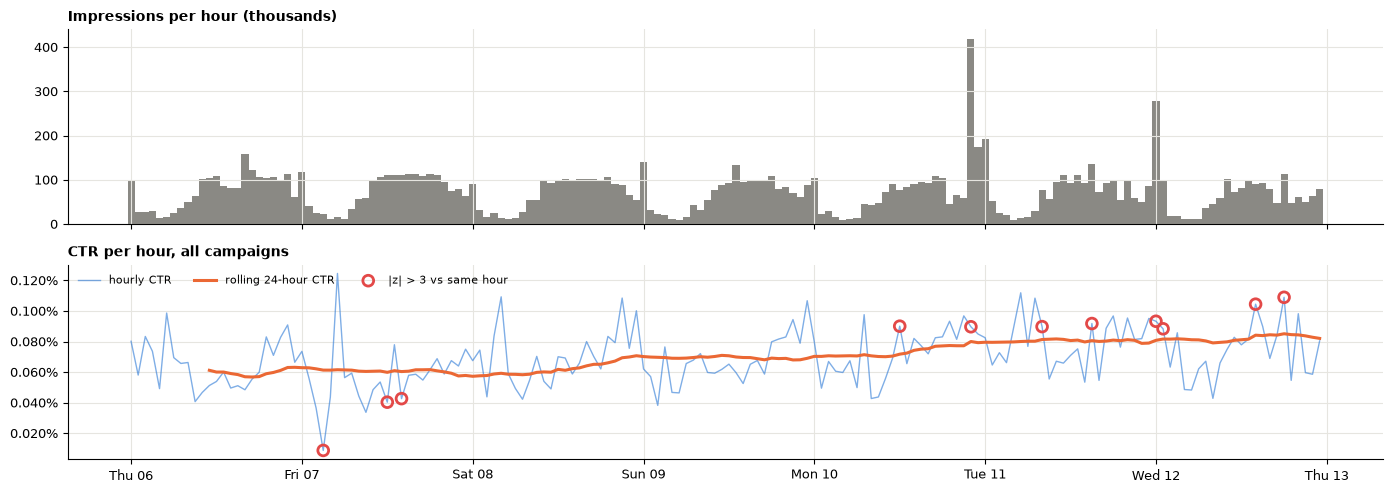

In [8]:
# CELL 8: 168-hour series, rolling 24h, same-hour baseline z-scores
S = H.groupby(["date", "hour"])[SUMS].sum().reset_index()
S["ts"] = S.date + pd.to_timedelta(S.hour, "h")
S = kpis(S.sort_values("ts").reset_index(drop=True))
S["ctr_24h"] = S.clicks.rolling(24, min_periods=12).sum() / S.imps.rolling(24, min_periods=12).sum()
# same hour on the OTHER days as the baseline (leave-one-out)
hour_tot = S.groupby("hour")[["clicks", "imps"]].transform("sum")
base = (hour_tot.clicks - S.clicks) / (hour_tot.imps - S.imps)
S["ctr_same_hour_baseline"] = base
S["ctr_z"] = (S.ctr - base) / np.sqrt(base * (1 - base) / S.imps)
imp_base = S.groupby("hour").imps.transform(lambda s: (s.sum() - s) / (len(s) - 1))
imp_sd = S.groupby("hour").imps.transform("std")
S["imps_z"] = (S.imps - imp_base) / imp_sd
S["flag"] = (S[["ctr_z", "imps_z"]].abs() > Z_FLAG).any(axis=1)
odd_hours = S[S.flag][["ts", "imps", "clicks", "ctr", "ctr_same_hour_baseline", "ctr_z", "imps_z"]]
print(f"Unusual hours (|z| > {Z_FLAG:g} vs the same hour on other days): {len(odd_hours)} of {len(S)}")
display(odd_hours.style.format({"imps": "{:,.0f}", "clicks": "{:,.0f}", "ctr": "{:.3%}",
                                "ctr_same_hour_baseline": "{:.3%}", "ctr_z": "{:+.1f}", "imps_z": "{:+.1f}"}))

if plt:
    fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
    axes[0].bar(S.ts, S.imps / 1e3, width=1 / 24, color=GREY)
    axes[0].set_title("Impressions per hour (thousands)")
    axes[1].plot(S.ts, S.ctr, color=BLUE, lw=1, alpha=0.6, label="hourly CTR")
    axes[1].plot(S.ts, S.ctr_24h, color=ORANGE, lw=2.2, label="rolling 24-hour CTR")
    f = S[S.flag]
    axes[1].scatter(f.ts, f.ctr, s=60, facecolor="none", edgecolor=RED, lw=2, zorder=5,
                    label=f"|z| > {Z_FLAG:g} vs same hour")
    axes[1].yaxis.set_major_formatter(pct3())
    axes[1].set_title("CTR per hour, all campaigns")
    axes[1].legend(fontsize=8, frameon=False, ncol=3, loc="upper left")
    axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d"))
    fig.tight_layout()
    save(fig, "04_hourly_series")
    plt.show()

### 6. Pacing: how each campaign spends through the day

For the **performance and pacing** tab: the share of each campaign's daily spend that is gone by each hour. **Even pacing** follows the diagonal, spending 1/24 per hour. A curve well **above** the diagonal spends early (*ASAP*), and a curve that flattens early **ran out of budget** before the day ended. A day whose total is far below the others (see the daily table) is the other sign of a budget cap.

,share spent by 12:00,share spent by 18:00,max gap vs even pacing,days with <5% of spend after 20:00
advertiser_id,,,,
1458,31%,67%,21.8%,0
3358,49%,76%,24.5%,4
3386,31%,65%,20.2%,0
3427,32%,69%,20.1%,1
3476,46%,81%,12.1%,3


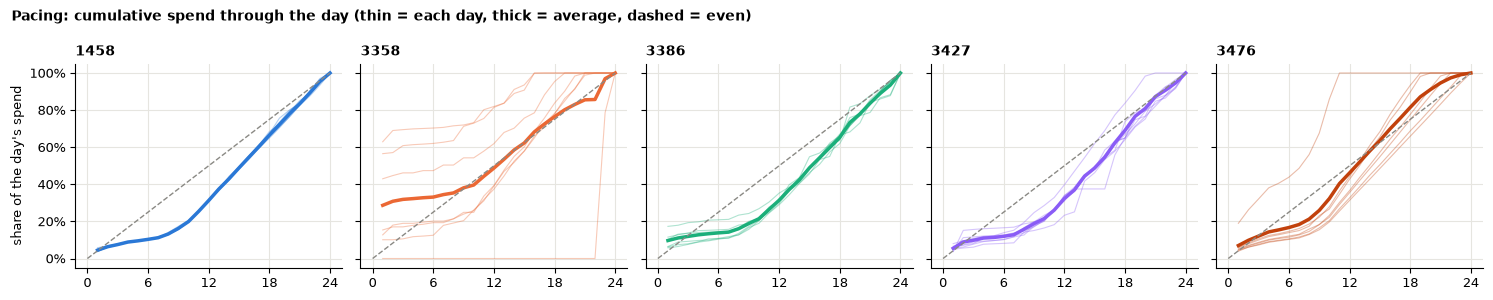

In [9]:
# CELL 9: cumulative share of daily spend by hour, per campaign (average over the 7 days) + per day spread
pace = H.groupby(["advertiser_id", "date", "hour"]).spend.sum().unstack("hour", fill_value=0)
pace = pace.div(pace.sum(axis=1), axis=0).cumsum(axis=1)
pace_avg = pace.groupby("advertiser_id").mean()
even = np.arange(1, 25) / 24
pacing = pd.DataFrame({
    "share spent by 12:00": pace_avg[11],
    "share spent by 18:00": pace_avg[17],
    "max gap vs even pacing": (pace_avg - even).abs().max(axis=1),
    "days with <5% of spend after 20:00": (1 - pace[19] < 0.05).groupby("advertiser_id").sum()})
display(pacing.style.format({"share spent by 12:00": "{:.0%}", "share spent by 18:00": "{:.0%}",
                             "max gap vs even pacing": "{:.1%}"}))
if plt:
    fig, axes = plt.subplots(1, len(pace_avg), figsize=(3 * len(pace_avg), 3), sharey=True)
    for ax, (adv, c) in zip(np.atleast_1d(axes), zip(pace_avg.index, CAMP_COLORS)):
        for d in pace.loc[adv].itertuples(index=False):
            ax.plot(range(1, 25), d, color=c, lw=0.8, alpha=0.35)
        ax.plot(range(1, 25), pace_avg.loc[adv], color=c, lw=2.5)
        ax.plot([0, 24], [0, 1], color=GREY, ls="--", lw=1)
        ax.set_title(str(adv))
        ax.set_xticks([0, 6, 12, 18, 24])
        ax.yaxis.set_major_formatter(mt.PercentFormatter(1.0))
    np.atleast_1d(axes)[0].set_ylabel("share of the day's spend")
    fig.suptitle("Pacing: cumulative spend through the day (thin = each day, thick = average, dashed = even)",
                 x=0.01, ha="left", fontweight="bold", fontsize=10)
    fig.tight_layout()
    save(fig, "04_pacing")
    plt.show()

In [10]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

## Findings

Generated from the numbers above.

In [11]:
# CELL 10: findings
dA = daily["ALL"]
ht = hour_tests.set_index("campaign")
a = ht.loc["ALL"].copy()
a["best_hour"], a["worst_hour"] = int(a.best_hour), int(a.worst_hour)
bh = by_hour
best_h, worst_h = bh.loc[a.best_hour], bh.loc[a.worst_hour]
bhr, whr = int(a.best_hour), int(a.worst_hour)
overlap = best_h.ctr_lo <= worst_h.ctr_hi
peak = int(bh.imps.idxmax())
F = [
    f"**Hour of day matters.** CTR across all campaigns peaks at {bhr:02d}:00 ({best_h.ctr:.3%}, 95% CI "
    f"{best_h.ctr_lo:.3%}–{best_h.ctr_hi:.3%}) and is lowest at {whr:02d}:00 ({worst_h.ctr:.3%}, "
    f"{worst_h.ctr_lo:.3%}–{worst_h.ctr_hi:.3%}). "
    + (f"Chi-square p = {a.p_value:.2g}. " if a.p_value == a.p_value else "")
    + ("The intervals overlap, so treat the gap with caution." if overlap else
       "The intervals don't overlap: a real daily rhythm and a candidate for dayparting (bid adjustments by hour)."),
    (f"**Volume and response peak at different times.** The most impressions are bought at {peak:02d}:00 "
     f"({bh.loc[peak, 'imp_share']:.1%} of the day), while CTR is best at {bhr:02d}:00. Spend follows "
     f"volume, not response." if abs(peak - bhr) > 1 else
     f"**Volume and response peak together** around {peak:02d}:00 ({bh.loc[peak, 'imp_share']:.1%} of the day's "
     f"impressions): the busiest hour is also the most responsive."),
    "**Unusual days:** " + ("none. Every campaign-day is within ±%g z of its baseline." % Z_FLAG if flags.empty else
        "; ".join(f"{'all campaigns' if r.campaign == 'ALL' else r.campaign} on {r.date:%a %d %b} (" + ", ".join(
            f"{n} z = {getattr(r, c):+.1f}" for n, c in (("CTR", "ctr_z"), ("impressions", "imps_z"), ("spend", "spend_z"))
            if getattr(r, c) == getattr(r, c) and abs(getattr(r, c)) > Z_FLAG) + ")" for r in flags.itertuples())
        + ". Check budget, pacing and inventory on these days before reading them as a trend."),
    f"**The week overall:** daily CTR ranges {dA.ctr.min():.3%}–{dA.ctr.max():.3%} against a 7-day CTR of "
    f"{dA.ctr_7d.iloc[-1]:.3%}. Win rate ranges {dA.win_rate.min():.1%}–{dA.win_rate.max():.1%}.",
    "**Pacing:** " + "; ".join(f"{adv} spends {r['share spent by 12:00']:.0%} by noon"
                                + (f", {int(r['days with <5% of spend after 20:00'])} day(s) nearly stop after 20:00"
                                   if r['days with <5% of spend after 20:00'] else "")
                                for adv, r in pacing.iterrows()) + ".",
    "**Limits.** With 7 days, each weekday appears once and the 7-day window only fills on the last day. So weekday "
    "effects aren't measurable here, and the rolling average is a baseline rather than a trend. The hourly "
    "pattern (168 hours) is the reliable signal.",
]
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
save_story("04_time_patterns", [
    {"title": f"CTR peaks at {bhr:02d}:00 and bottoms at {whr:02d}:00",
     "number": f"{best_h.ctr:.3%} (95% CI {best_h.ctr_lo:.3%}–{best_h.ctr_hi:.3%}) vs {worst_h.ctr:.3%} "
               f"({worst_h.ctr_lo:.3%}–{worst_h.ctr_hi:.3%}); busiest hour {peak:02d}:00 with {bh.loc[peak, 'imp_share']:.1%} of impressions",
     "chart": "04_hour_of_day.png", "confidence": conf_from_p(a.p_value) if a.p_value == a.p_value else
               ("Medium (intervals don't overlap)" if not overlap else "Low (intervals overlap)"),
     "meaning": "Dayparting: raise bids in the responsive hours and lower them in the weak ones, then measure the "
                "change in cost per click."},
    {"title": "Unusual days: " + (", ".join(sorted({f"{r.campaign} on {r.date:%d %b}" for r in flags.itertuples()
                                                     if r.campaign != 'ALL'})) or "none"),
     "number": ("; ".join(f"{r.campaign} {r.date:%d %b}: impressions z = {r.imps_z:+.1f}, CTR z = {r.ctr_z:+.1f}"
                          for r in flags[flags.campaign != 'ALL'].itertuples()) or "all days within ±3 z"),
     "chart": "04_daily_by_campaign.png", "confidence": "High for |z| > 3, but only 7 days of baseline",
     "meaning": "A volume spike or drop usually means a budget or pacing change, not a market change. The daily "
                "report should alert on these automatically."},
])

1. **Hour of day matters.** CTR across all campaigns peaks at 23:00 (0.087%, 95% CI 0.080%–0.095%) and is lowest at 09:00 (0.053%, 0.046%–0.060%). The intervals don't overlap: a real daily rhythm and a candidate for dayparting (bid adjustments by hour).
2. **Volume and response peak at different times.** The most impressions are bought at 00:00 (8.3% of the day), while CTR is best at 23:00. Spend follows volume, not response.
3. **Unusual days:** all campaigns on Sat 08 Jun (CTR z = +5.3); all campaigns on Mon 10 Jun (CTR z = +7.8, spend z = +8.1); all campaigns on Tue 11 Jun (CTR z = +5.5); all campaigns on Wed 12 Jun (CTR z = +5.9); 1458 on Sat 08 Jun (CTR z = +3.4); 1458 on Tue 11 Jun (CTR z = +3.3); 3358 on Sun 09 Jun (impressions z = -4.4, spend z = -4.3); 3358 on Mon 10 Jun (CTR z = +9.9, impressions z = +15.1, spend z = +19.9); 3358 on Wed 12 Jun (CTR z = +3.8); 3386 on Sun 09 Jun (spend z = +10.7); 3386 on Tue 11 Jun (CTR z = +4.1); 3386 on Wed 12 Jun (CTR z = +5.0); 3427 on Sat 08 Jun (CTR z = +3.1); 3476 on Fri 07 Jun (CTR z = -3.3); 3476 on Sat 08 Jun (CTR z = +3.7); 3476 on Mon 10 Jun (spend z = -3.1); 3476 on Wed 12 Jun (impressions z = -5.3, spend z = -5.4). Check budget, pacing and inventory on these days before reading them as a trend.
4. **The week overall:** daily CTR ranges 0.058%–0.082% against a 7-day CTR of 0.072%. Win rate ranges 13.9%–34.8%.
5. **Pacing:** 1458 spends 31% by noon; 3358 spends 49% by noon, 4 day(s) nearly stop after 20:00; 3386 spends 31% by noon; 3427 spends 32% by noon, 1 day(s) nearly stop after 20:00; 3476 spends 46% by noon, 3 day(s) nearly stop after 20:00.
6. **Limits.** With 7 days, each weekday appears once and the 7-day window only fills on the last day. So weekday effects aren't measurable here, and the rolling average is a baseline rather than a trend. The hourly pattern (168 hours) is the reliable signal.

Saved 2 story candidate(s) to reports/findings/04_time_patterns.json
